# Towards Transparent Quantum Execution: A New Framework in Qiskit

In [7]:
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler, Estimator, Executor, QuantumProgram
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

try:
    service = QiskitRuntimeService()
    ibm_backend = service.backend("ibm_pittsburgh")
except:
    ibm_backend = None

if USE_REAL_BACKEND := False:
    backend = ibm_backend
else:
    backend = FakeManilaV2()

print(f"Backend: {backend.name}, {backend.num_qubits} qubits")

qiskit_runtime_service.__init__:WARNING:2026-11-17 13:54:48,172: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (premium, internal), the available account instances are: engine-premium-eu, engine-internal-eu, engine-internal-us, engine-premium-us. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-17 13:54:48,177: Using instance: engine-premium-us, plan: premium


Backend: fake_manila, 5 qubits


## Primitives

### Sampler: Hello World

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# GHZ circuit: |000⟩ + |111⟩
qc = QuantumCircuit(3)
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.measure_all()

pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
isa_qc = pm.run(qc)

sampler = Sampler(mode=backend)
job = sampler.run([isa_qc], shots=4096)
result = job.result()

# One BitArray per classical register
data = result[0].data
print(f"Classical registers: {list(data.keys())}")
print(f"BitArray: shape={data.meas.shape}, num_shots={data.meas.num_shots}, num_bits={data.meas.num_bits}")
print()

# Convenience: counts dict
counts = data.meas.get_counts()
print("Counts:", counts)
print()

# Direct computation on bit data: GHZ fidelity
ghz_frac = (counts.get("000", 0) + counts.get("111", 0)) / sum(counts.values())
print(f"GHZ fidelity (lower bound): {ghz_frac:.3f}")

Classical registers: ['meas']
BitArray: shape=(), num_shots=4096, num_bits=3

Counts: {'000': 1740, '111': 1753, '101': 55, '011': 182, '110': 78, '100': 174, '010': 43, '001': 71}

GHZ fidelity (lower bound): 0.853


### Estimator: Hello World

In [3]:
from qiskit.quantum_info import SparsePauliOp

# Same GHZ state, without measurements
qc_est = QuantumCircuit(3)
qc_est.h(0)
qc_est.cx(0, 1)
qc_est.cx(1, 2)
isa_est = pm.run(qc_est)

# Observables must be mapped to physical qubits via the transpiler layout
observable = SparsePauliOp("ZZI").apply_layout(isa_est.layout)

estimator = Estimator(mode=backend)
job = estimator.run([(isa_est, observable)])
result = job.result()

evs = result[0].data.evs
stds = result[0].data.stds
print(f"⟨ZZI⟩ = {evs:.4f} ± {stds:.4f}")

⟨ZZI⟩ = 0.9620 ± 0.0130


### Broadcasting

evs shape:  (20, 2)  — broadcast of params (20, 1) × observables (2,)
stds shape: (20, 2)


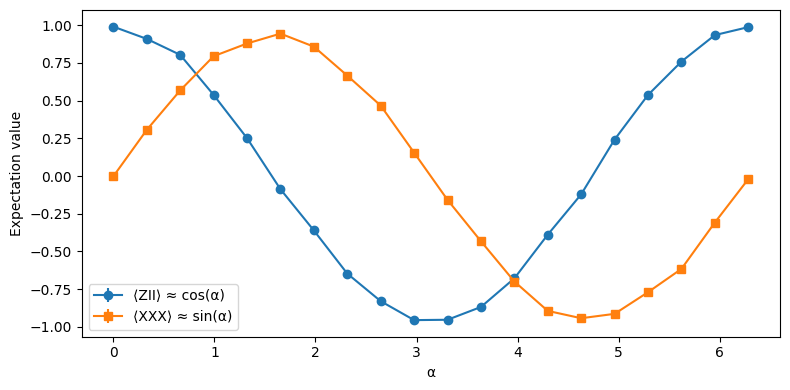

In [4]:
import matplotlib.pyplot as plt
from qiskit.circuit import Parameter

# Parametrized circuit with one angle
alpha = Parameter("α")
qc_param = QuantumCircuit(3)
qc_param.ry(alpha, 0)
qc_param.cx(0, 1)
qc_param.cx(1, 2)

isa_param = pm.run(qc_param)

# State is cos(α/2)|000⟩ + sin(α/2)|111⟩
# ⟨ZII⟩ = cos(α),  ⟨XXX⟩ = sin(α)
obs_z = SparsePauliOp("ZII").apply_layout(isa_param.layout)
obs_x = SparsePauliOp("XXX").apply_layout(isa_param.layout)

# Sweep α over 20 values → parameter_values shape (20, 1, 1) → extrinsic (20, 1)
alpha_vals = np.linspace(0, 2 * np.pi, 20)
params = alpha_vals.reshape(20, 1, 1)

# Broadcasting: params (20, 1) × observables (2,) → evs shape (20, 2)
estimator = Estimator(mode=backend)
job = estimator.run([(isa_param, [obs_z, obs_x], params)])
result = job.result()

evs = result[0].data.evs
stds = result[0].data.stds
print(f"evs shape:  {evs.shape}  — broadcast of params (20, 1) × observables (2,)")
print(f"stds shape: {stds.shape}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(alpha_vals, evs[:, 0], yerr=stds[:, 0], fmt="o-", label="⟨ZII⟩ ≈ cos(α)")
ax.errorbar(alpha_vals, evs[:, 1], yerr=stds[:, 1], fmt="s-", label="⟨XXX⟩ ≈ sin(α)")
ax.set_xlabel("α")
ax.set_ylabel("Expectation value")
ax.legend()
plt.tight_layout()

### Options

In [5]:
from rich.pretty import pprint

if ibm_backend is not None:
    sampler = Sampler(mode=ibm_backend)
    pprint(sampler.options)

qiskit_runtime_service.backends:WARNING:2026-11-17 13:58:16,067: Using instance: engine-premium-us, plan: premium


<RuntimeJobV2('dbua7i2e8crs738ba4kg', 'executor')>
BitArray: shape=(20,), num_shots=4096, num_bits=3


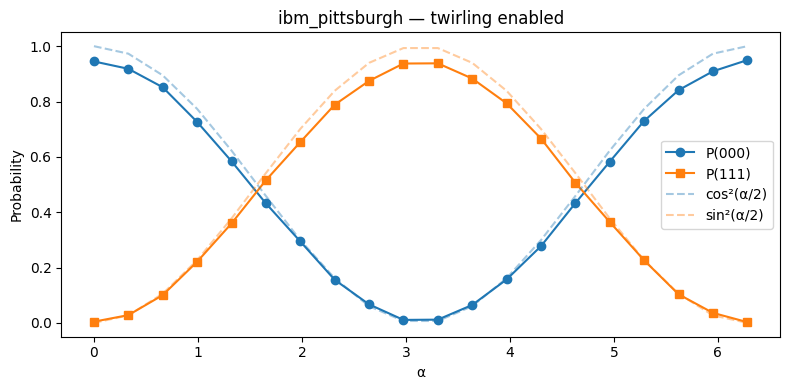

In [11]:
if ibm_backend is not None:
    # Parametric circuit with measurements for sampler
    qc_param_meas = qc_param.copy()
    qc_param_meas.measure_all()

    pm_ibm = generate_preset_pass_manager(optimization_level=1, backend=ibm_backend)
    isa_param_ibm = pm_ibm.run(qc_param_meas)

    sampler_ibm = Sampler(mode=ibm_backend)
    sampler_ibm.options.twirling.enable_gates = True
    sampler_ibm.options.twirling.enable_measure = True
    sampler_ibm.options.execution.scheduler_timing = True

    # Sweep α over 20 values
    params = alpha_vals.reshape(20, 1)
    job = sampler_ibm.run([(isa_param_ibm, params)], shots=4096)
    print(job)
    result = job.result()

    data = result[0].data.meas
    print(f"BitArray: shape={data.shape}, num_shots={data.num_shots}, num_bits={data.num_bits}")

    # Extract P(000) and P(111) separately per angle
    p000, p111 = [], []
    for i in range(len(alpha_vals)):
        counts = data[i].get_counts()
        total = sum(counts.values())
        p000.append(counts.get("000", 0) / total)
        p111.append(counts.get("111", 0) / total)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(alpha_vals, p000, "o-", label="P(000)")
    ax.plot(alpha_vals, p111, "s-", label="P(111)")
    ax.plot(alpha_vals, np.cos(alpha_vals / 2) ** 2, "--", color="C0", alpha=0.4, label="cos²(α/2)")
    ax.plot(alpha_vals, np.sin(alpha_vals / 2) ** 2, "--", color="C1", alpha=0.4, label="sin²(α/2)")
    ax.set_xlabel("α")
    ax.set_ylabel("Probability")
    ax.set_title(f"{ibm_backend.name} — twirling enabled")
    ax.legend()
    plt.tight_layout()

In [10]:
result.metadata

{'executor': Metadata(chunk_timing=[ChunkSpan(start=datetime.datetime(2026, 11, 17, 18, 55, 58, 331396, tzinfo=datetime.timezone.utc), stop=datetime.datetime(2026, 11, 17, 18, 56, 20, 758064, tzinfo=datetime.timezone.utc), parts=[ChunkPart(idx_item=0, size=640)])]),
 'options': {'default_shots': 4096,
  'dynamical_decoupling': {'enable': False,
   'extra_slack_distribution': 'middle',
   'scheduling_method': 'alap',
   'sequence_type': 'XX',
   'skip_reset_qubits': False},
  'environment': {'image': None,
   'job_tags': [],
   'log_level': 'WARNING',
   'max_execution_time': None,
   'private': False},
  'execution': {'init_qubits': True,
   'meas_type': 'classified',
   'rep_delay': None,
   'scheduler_timing': False,
   'stretch_values': False},
  'experimental': {},
  'max_execution_time': None,
  'simulator': {'angle_decimals': 5,
   'layer_noise_model': None,
   'seed_simulator': None,
   'warn_absent': True},
  'twirling': {'enable_gates': True,
   'enable_measure': True,
   'gro

## Executor

### Hello World

In [8]:
# Executor + CircuitItem: equivalent to a bare sampler job
program = QuantumProgram(shots=4096)
program.append_circuit_item(isa_qc)

executor = Executor(mode=backend)
job = executor.run(program)
result = job.result()

# Raw bool array: (shots, num_bits)
item = result[0]
meas = item["meas"]
print(f"meas shape: {meas.shape}  — (num_shots, num_bits)")
print(f"meas dtype: {meas.dtype}")

meas shape: (4096, 3)  — (num_shots, num_bits)
meas dtype: bool


### Samplomatic

In [ ]:
from samplomatic import build
from samplomatic.transpiler import generate_boxing_pass_manager

# Box the ISA circuit for Pauli twirling
boxing_pm = generate_boxing_pass_manager(
    enable_gates=True,
    enable_measures=True,
    twirling_strategy="active_circuit",
    twirling_group="pauli",
)
boxed = boxing_pm.run(isa_qc)

# Build the template circuit and samplex (randomization specification)
template, samplex = build(boxed)
print(f"Template parameters: {template.num_parameters}")

In [ ]:
template.draw("mpl")

In [ ]:
samplex.draw()

In [ ]:
# Build a twirled QuantumProgram
num_randomizations = 32
shots_per_rand = 128

program = QuantumProgram(shots=shots_per_rand)
program.append_samplex_item(template, samplex, shape=(num_randomizations,))

executor = Executor(mode=backend)
job = executor.run(program)
result = job.result()

# Raw result: bool arrays
item = result[0]
print(f"Result keys: {list(item.keys())}")
print(f"meas shape: {item['meas'].shape}  — (num_rand, shots_per_rand, num_bits)")
print(f"measurement_flips shape: {item['measurement_flips.meas'].shape}")

In [ ]:
# Post-process: undo measurement twirling via XOR
meas = item["meas"] ^ item["measurement_flips.meas"]

# Collapse randomizations into shot axis
meas_flat = meas.reshape(-1, meas.shape[-1])  # (num_rand * shots_per_rand, num_bits)

# Count outcomes directly with numpy
outcomes, counts = np.unique(np.packbits(meas_flat, axis=-1, bitorder="little"), axis=0, return_counts=True)
print(f"Total shots: {meas_flat.shape[0]}")
for outcome, count in sorted(zip(outcomes, counts), key=lambda x: -x[1]):
    bits = "".join(str(b) for b in np.unpackbits(outcome, bitorder="little")[:meas_flat.shape[-1]])
    print(f"  {bits}: {count}")

## Primitives via Executor

In [ ]:
# Under the hood, Sampler and Estimator convert PUBs into a QuantumProgram
# and submit via Executor. We can call the same prepare() step directly.
from qiskit_ibm_runtime.executor_sampler.prepare import prepare

sampler = Sampler(mode=backend)
quantum_program, executor_options = prepare(
    [isa_qc], sampler.options, shots=1024, backend=backend
)

print(f"Type: {type(quantum_program).__name__}")
print(f"Items: {len(quantum_program.items)}")
print(f"Shots: {quantum_program.shots}")
print(f"Item type: {type(quantum_program.items[0]).__name__}")
print()

# Submit the same QuantumProgram directly to Executor
executor = Executor(mode=backend)
job = executor.run(quantum_program)
result = job.result()
print(f"Executor result meas shape: {result[0]['meas'].shape}")

## Beyond: BackendV3

In [ ]:
import numpy as np
from qiskit.quantum_program import build, shot_loop, constant
from qiskit.circuit import QuantumCircuit, Parameter, ClassicalRegister, QuantumRegister
from qiskit.providers.basic_provider import BasicProgramSimulator

In [ ]:
import numpy as np
from qiskit.quantum_program import build, shot_loop, constant
from qiskit.circuit import QuantumCircuit, Parameter, ClassicalRegister, QuantumRegister
from qiskit.providers.basic_provider import BasicProgramSimulator # BackendV3

circuit = QuantumCircuit(4)
circuit.rx(a := Parameter("a"), 0)
circuit.cx(0, 1)
circuit.rx(2 * a, 0)
circuit.cx(1, 2)
circuit.cx(2, 3)
circuit.measure_all()

sweep = constant(np.linspace(-np.pi, np.pi, 50)[:, None])
raw_data = shot_loop([circuit], shots=1000, parameter_values=[sweep])

quantum_program = build(raw_data)

job = BasicProgramSimulator().run(quantum_program)
data = job.result()

In [ ]:
print(quantum_program.listing())

In [ ]:
quantum_program.draw()

raw_data = shot_loop([circuit], shots=1000, parameter_values=[sweep])

zs = np.array([
    [1,0,0,0], 
    [0,1,1,1], 
    [1,1,1,1]], dtype=bool)[:,None,None,:]
per_shot_parities = (raw_data[0]["meas"] & zs).parity(axis=3)
proto_evs = per_shot_parities.mean(axis=2)
evs = 1 - 2 * proto_evs

quantum_program = build({
    "my_evs": evs, 
    "sweep": sweep, 
    "all_shots": raw_data
})

In [ ]:
quantum_program.draw()

In [ ]:
quantum_program = build({"my_evs": evs, "sweep": sweep, "all_shots": raw_data})

job = BasicProgramSimulator().run(quantum_program)
data = job.result()

In [ ]:
import matplotlib.pyplot as plt

plt.plot(data["sweep"], data["my_evs"].T, label=["ZIII", "ZZZZ", "IZZZ"])
plt.xlabel("Parameter('a') [rad]")
plt.ylabel("Expectation Value")
plt.legend()